In [2]:
print("データサイエンス、始めます")

データサイエンス、始めます


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_breast_cancer

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.grid": True,
    "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
})

raw = load_breast_cancer(as_frame=True)
df = raw.frame.copy()
df["group"] = df["target"].map({0: "malignant", 1: "benign"})
print(df.shape)
print(df["group"].value_counts())

(569, 32)
group
benign       357
malignant    212
Name: count, dtype: int64


In [4]:
cols = ["mean radius", "mean area", "mean smoothness"]
print(df[cols].describe().round(2))

       mean radius  mean area  mean smoothness
count       569.00     569.00           569.00
mean         14.13     654.89             0.10
std           3.52     351.91             0.01
min           6.98     143.50             0.05
25%          11.70     420.30             0.09
50%          13.37     551.10             0.10
75%          15.78     782.70             0.11
max          28.11    2501.00             0.16


In [6]:
x = df["mean area"]
print("平均   :", round(x.mean(), 1))
print("中央値 :", round(x.median(), 1))
print("標準偏差:", round(x.std(), 1))
print("四分位範囲(IQR):", round(x.quantile(0.75) - x.quantile(0.25), 1))
print("歪度   :", round(stats.skew(x), 2), "（0 なら左右対称、正なら右に長い裾）")

平均   : 654.9
中央値 : 551.1
標準偏差: 351.9
四分位範囲(IQR): 362.4
歪度   : 1.64 （0 なら左右対称、正なら右に長い裾）


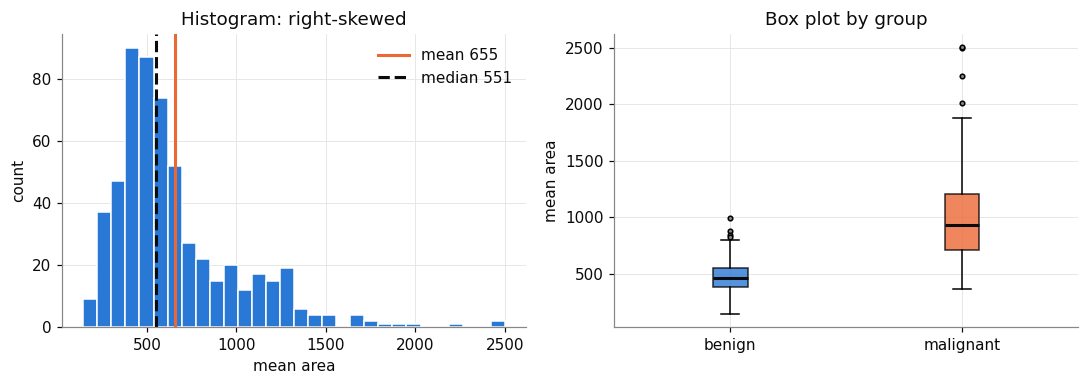

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(x, bins=30, color=BLUE, edgecolor="white")
ax[0].axvline(x.mean(), color=ORANGE, lw=2, label=f"mean {x.mean():.0f}")
ax[0].axvline(x.median(), color=INK, lw=2, ls="--", label=f"median {x.median():.0f}")
ax[0].set(xlabel="mean area", ylabel="count", title="Histogram: right-skewed")
ax[0].legend(frameon=False)
data_by_group = [df.loc[df.group == g, "mean area"] for g in ["benign", "malignant"]]
bp = ax[1].boxplot(data_by_group, patch_artist=True,
                   medianprops=dict(color=INK, lw=2), flierprops=dict(markerfacecolor=MUTED, markersize=3))
for patch, c in zip(bp["boxes"], [BLUE, ORANGE]):
    patch.set(facecolor=c, alpha=0.8)
ax[1].set(ylabel="mean area", title="Box plot by group", xticks=[1, 2], xticklabels=["benign", "malignant"])
plt.tight_layout()
plt.show()

In [8]:
x = df["mean perimeter"]
print("平均   :", round(x.mean(), 1))
print("中央値 :", round(x.median(), 1))
print("標準偏差:", round(x.std(), 1))
print("四分位範囲(IQR):", round(x.quantile(0.75) - x.quantile(0.25), 1))

平均   : 92.0
中央値 : 86.2
標準偏差: 24.3
四分位範囲(IQR): 28.9


In [9]:
x = df["mean perimeter"]
iqr = x.quantile(75) - x.quantile(25)
print(iqr)

ValueError: percentiles should all be in the interval [0, 1]

In [10]:
x = df["mean perimeter"]
iqr = x.quantile(0.75) - x.quantile(0.25)
print(iqr)

28.929999999999993


良性の mean radius: 平均 12.15, 標準偏差 1.78
z にした後 平均: 0.0  標準偏差: 1.0


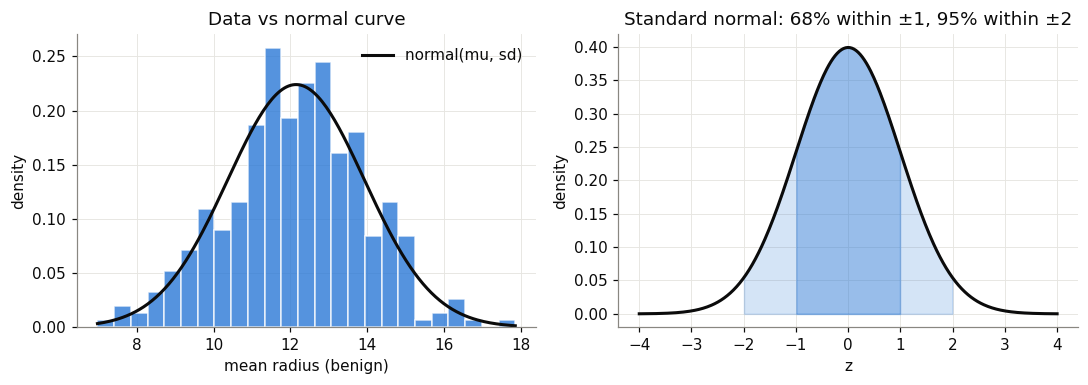

±1σ に入る割合（理論）: 0.6827
±2σ に入る割合（理論）: 0.9545
±1σ に入る割合（実データ）: 0.6835
±2σ に入る割合（実データ）: 0.958


In [12]:
benign = df.loc[df.group == "benign", "mean radius"]
mu, sd = benign.mean(), benign.std()
print(f"良性の mean radius: 平均 {mu:.2f}, 標準偏差 {sd:.2f}")
z = (benign - mu) / sd
print("z にした後 平均:", round(z.mean(), 3), " 標準偏差:", round(z.std(), 3))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
grid = np.linspace(benign.min(), benign.max(), 200)
ax[0].hist(benign, bins=25, density=True, color=BLUE, edgecolor="white", alpha=0.8)
ax[0].plot(grid, stats.norm.pdf(grid, mu, sd), color=INK, lw=2, label="normal(mu, sd)")
ax[0].set(xlabel="mean radius (benign)", ylabel="density", title="Data vs normal curve")
ax[0].legend(frameon=False)
g = np.linspace(-4, 4, 400)
ax[1].plot(g, stats.norm.pdf(g), color=INK, lw=2)
for k, a in [(1, 0.35), (2, 0.2)]:
    m = (g >= -k) & (g <= k)
    ax[1].fill_between(g[m], stats.norm.pdf(g[m]), color=BLUE, alpha=a)
ax[1].set(xlabel="z", ylabel="density", title="Standard normal: 68% within ±1, 95% within ±2")
plt.tight_layout()
plt.show()
print("±1σ に入る割合（理論）:", round(stats.norm.cdf(1) - stats.norm.cdf(-1), 4))
print("±2σ に入る割合（理論）:", round(stats.norm.cdf(2) - stats.norm.cdf(-2), 4))
print("±1σ に入る割合（実データ）:", round((z.abs() <= 1).mean(), 4))
print("±2σ に入る割合（実データ）:", round((z.abs() <= 2).mean(), 4))

In [13]:
z_score = (17.99 - mu) / sd
print(f"17.99 の z スコア: {z_score:.2f}")

17.99 の z スコア: 3.28


母集団の平均を含んだ区間: 96 / 100


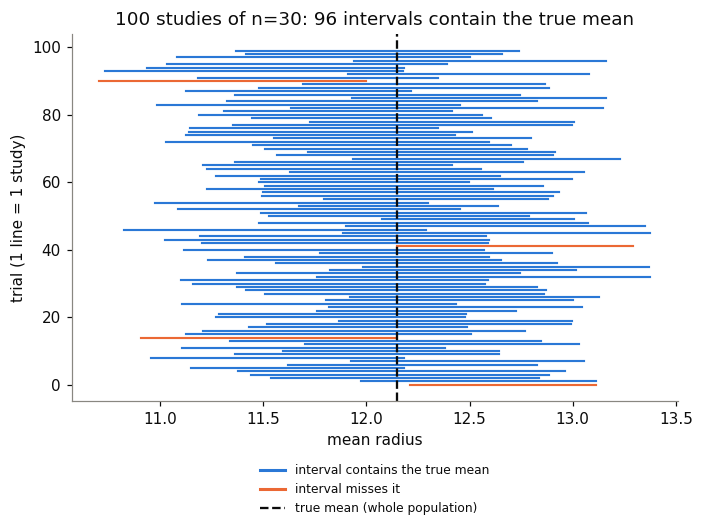

In [15]:
rng = np.random.default_rng(42)
pop_mean = benign.mean()
n = 30
trials = 100
rows = []
for i in range(trials):
    s = rng.choice(benign.to_numpy(), size=n, replace=False)
    m, se = s.mean(), s.std(ddof=1) / np.sqrt(n)
    h = stats.t.ppf(0.975, n - 1) * se
    rows.append((m - h, m + h))
ci = np.array(rows)
hit = (ci[:, 0] <= pop_mean) & (pop_mean <= ci[:, 1])
print(f"母集団の平均を含んだ区間: {hit.sum()} / {trials}")

fig, ax = plt.subplots(figsize=(6.5, 5))
for i, (lo, hi) in enumerate(ci):
    ax.plot([lo, hi], [i, i], color=BLUE if hit[i] else ORANGE, lw=1.4)
ax.axvline(pop_mean, color=INK, lw=1.5, ls="--")
ax.plot([], [], color=BLUE, lw=2, label="interval contains the true mean")
ax.plot([], [], color=ORANGE, lw=2, label="interval misses it")
ax.plot([], [], color=INK, lw=1.5, ls="--", label="true mean (whole population)")
ax.set(xlabel="mean radius", ylabel="trial (1 line = 1 study)",
       title=f"{trials} studies of n={n}: {hit.sum()} intervals contain the true mean")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=1, fontsize=8)
ax.grid(False)
plt.tight_layout()
plt.show()

母集団の平均を含んだ区間: 97 / 100


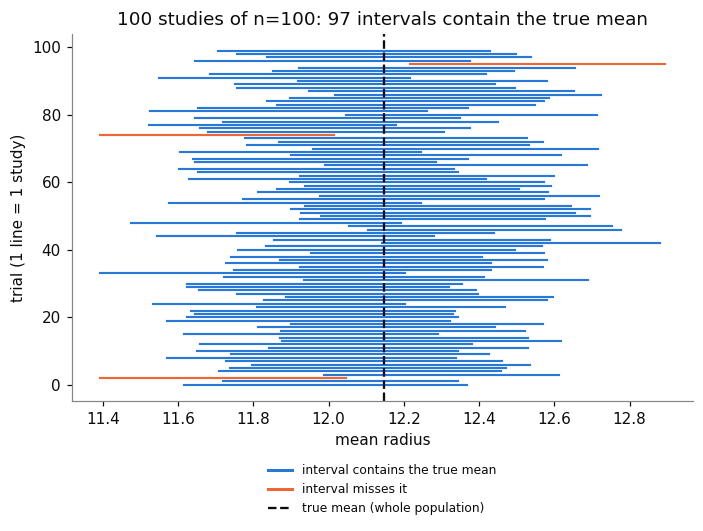

In [16]:
rng = np.random.default_rng(42)
pop_mean = benign.mean()
n = 100
trials = 100
rows = []
for i in range(trials):
    s = rng.choice(benign.to_numpy(), size=n, replace=False)
    m, se = s.mean(), s.std(ddof=1) / np.sqrt(n)
    h = stats.t.ppf(0.975, n - 1) * se
    rows.append((m - h, m + h))
ci = np.array(rows)
hit = (ci[:, 0] <= pop_mean) & (pop_mean <= ci[:, 1])
print(f"母集団の平均を含んだ区間: {hit.sum()} / {trials}")

fig, ax = plt.subplots(figsize=(6.5, 5))
for i, (lo, hi) in enumerate(ci):
    ax.plot([lo, hi], [i, i], color=BLUE if hit[i] else ORANGE, lw=1.4)
ax.axvline(pop_mean, color=INK, lw=1.5, ls="--")
ax.plot([], [], color=BLUE, lw=2, label="interval contains the true mean")
ax.plot([], [], color=ORANGE, lw=2, label="interval misses it")
ax.plot([], [], color=INK, lw=1.5, ls="--", label="true mean (whole population)")
ax.set(xlabel="mean radius", ylabel="trial (1 line = 1 study)",
       title=f"{trials} studies of n={n}: {hit.sum()} intervals contain the true mean")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=1, fontsize=8)
ax.grid(False)
plt.tight_layout()
plt.show()

mean fractal dimension: 観察された差 -0.00019, 並べ替え p = 0.7579（10000回中 7579 回。0 回なら p < 0.0001）, Welch p = 7.67e-01
mean smoothness: 観察された差 0.01042, 並べ替え p = 0.0000（10000回中 0 回。0 回なら p < 0.0001）, Welch p = 5.57e-19


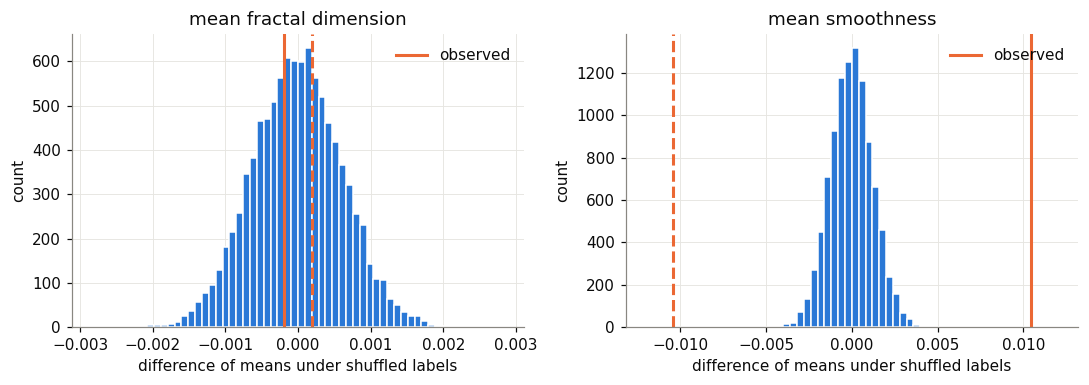

In [18]:
def permutation_diffs(feature, n_shuffle=10000, seed=0):
    a = df.loc[df.group == "benign", feature].to_numpy()
    b = df.loc[df.group == "malignant", feature].to_numpy()
    obs = b.mean() - a.mean()
    pool = np.concatenate([a, b])
    rng = np.random.default_rng(seed)
    diffs = np.empty(n_shuffle)
    for i in range(n_shuffle):
        rng.shuffle(pool)
        diffs[i] = pool[len(a):].mean() - pool[:len(a)].mean()
    return obs, diffs, (np.abs(diffs) >= abs(obs)).mean()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for a_, feature in zip(ax, ["mean fractal dimension", "mean smoothness"]):
    obs, diffs, p_perm = permutation_diffs(feature)
    welch = stats.ttest_ind(df.loc[df.group == "malignant", feature],
                            df.loc[df.group == "benign", feature], equal_var=False).pvalue
    print(f"{feature}: 観察された差 {obs:.5f}, 並べ替え p = {p_perm:.4f}（10000回中 {int(round(p_perm*10000))} 回。0 回なら p < 0.0001）, Welch p = {welch:.2e}")
    lim = max(abs(obs), abs(diffs).max()) * 1.15
    a_.hist(diffs, bins=60, range=(-lim, lim), color=BLUE, edgecolor="white")
    a_.axvline(obs, color=ORANGE, lw=2, label="observed")
    a_.axvline(-obs, color=ORANGE, lw=2, ls="--")
    a_.set(xlabel="difference of means under shuffled labels", ylabel="count", title=feature)
    a_.legend(frameon=False)
plt.tight_layout(); plt.show()

In [19]:
x = df["mean area"]
p5, p95 = x.quantile([0.05, 0.95])
low = x < p5
high = x > p95
print(f"5% 点 = {p5:.1f}, 95% 点 = {p95:.1f}")
print(f"外れ値の数: 下側 {int(low.sum())} + 上側 {int(high.sum())} = {int((low | high).sum())} / {len(x)}（{(low | high).mean():.1%}）")
print("下側の悪性の割合:", round((df.loc[low, "group"] == "malignant").mean(), 3))
print("上側の悪性の割合:", round((df.loc[high, "group"] == "malignant").mean(), 3))

5% 点 = 275.8, 95% 点 = 1309.8
外れ値の数: 下側 29 + 上側 29 = 58 / 569（10.2%）
下側の悪性の割合: 0.0
上側の悪性の割合: 1.0


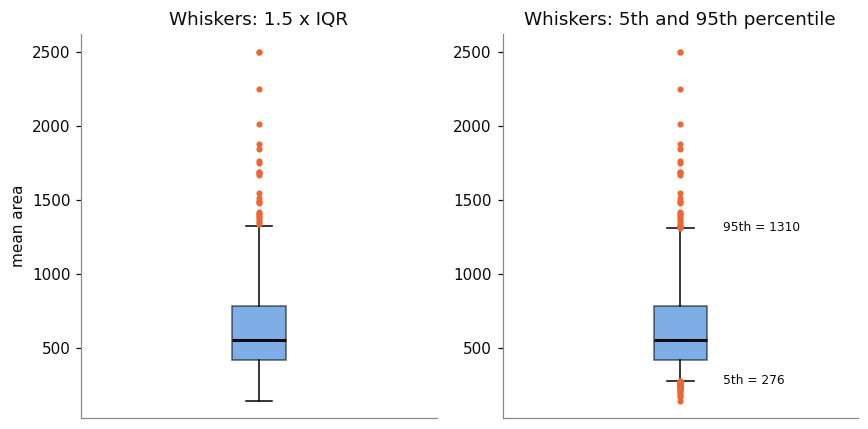

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].boxplot(x, whis=1.5, patch_artist=True, boxprops=dict(facecolor=BLUE, alpha=0.6),
              medianprops=dict(color=INK, lw=2), flierprops=dict(markerfacecolor=ORANGE, markeredgecolor=ORANGE, markersize=3))
ax[0].set(ylabel="mean area", title="Whiskers: 1.5 x IQR", xticks=[])
ax[1].boxplot(x, whis=(5, 95), patch_artist=True, boxprops=dict(facecolor=BLUE, alpha=0.6),
              medianprops=dict(color=INK, lw=2), flierprops=dict(markerfacecolor=ORANGE, markeredgecolor=ORANGE, markersize=3))
ax[1].set(title="Whiskers: 5th and 95th percentile", xticks=[])
ax[1].text(1.12, p95, f"95th = {p95:.0f}", va="center", fontsize=8)
ax[1].text(1.12, p5, f"5th = {p5:.0f}", va="center", fontsize=8)
for a_ in ax:
    a_.grid(False)
plt.tight_layout(); plt.show()

In [21]:
q1, q3 = x.quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out = (x < lo) | (x > hi)
print(f"IQR 法の範囲: {lo:.0f} 〜 {hi:.0f}")
print("外れ値と判定された数:", int(out.sum()), "/", len(x))
print("そのうち悪性の割合:", round((df.loc[out, "group"] == "malignant").mean(), 3))
print(f"平均 {x.mean():.1f} → 外れ値を除くと {x[~out].mean():.1f}")
print(f"中央値 {x.median():.1f} → 外れ値を除くと {x[~out].median():.1f}")

IQR 法の範囲: -123 〜 1326
外れ値と判定された数: 25 / 569
そのうち悪性の割合: 1.0
平均 654.9 → 外れ値を除くと 608.2
中央値 551.1 → 外れ値を除くと 537.3


In [22]:
def count_outliers(y):
    a, b = y.quantile([0.25, 0.75])
    w = b - a
    iqr_n = int(((y < a - 1.5 * w) | (y > b + 1.5 * w)).sum())
    l, h = y.quantile([0.05, 0.95])
    pct_n = int(((y < l) | (y > h)).sum())
    return iqr_n, pct_n

rng = np.random.default_rng(0)
reps, size = 1000, len(x)
res_out = {}
for name, gen in [("normal (no outliers)", lambda: rng.normal(0, 1, size)),
                  ("right-skewed (lognormal)", lambda: rng.lognormal(0, 0.5, size))]:
    counts = np.array([count_outliers(pd.Series(gen())) for _ in range(reps)])
    res_out[name] = counts.mean(axis=0)
res_out["real data (mean area)"] = [int(out.sum()), int((low | high).sum())]
print(pd.DataFrame(res_out, index=["IQR method", "percentile method"]).T.round(1))
print(f"（どれも {size} 個あたりの外れ値の数。実データの行は、1回だけの値）")

                          IQR method  percentile method
normal (no outliers)             4.3               58.0
right-skewed (lognormal)        21.7               58.0
real data (mean area)           25.0               58.0
（どれも 569 個あたりの外れ値の数。実データの行は、1回だけの値）


          raw  min-max (0-1)  z-score   log
mean   654.89           0.22    -0.00  6.36
std    351.91           0.15     1.00  0.48
min    143.50           0.00    -1.45  4.97
max   2501.00           1.00     5.25  7.82
歪度: {'raw': 1.64, 'min-max (0-1)': 1.64, 'z-score': 1.64, 'log': 0.28}


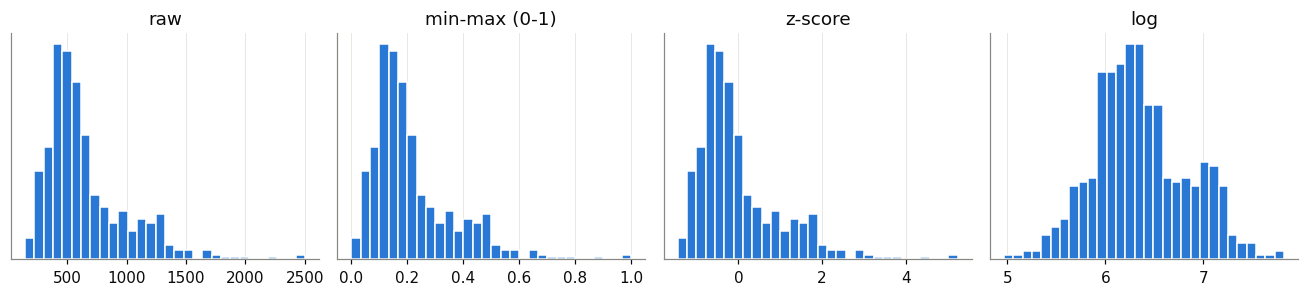

In [23]:
scaled = pd.DataFrame({
    "raw": x,
    "min-max (0-1)": (x - x.min()) / (x.max() - x.min()),
    "z-score": (x - x.mean()) / x.std(),
    "log": np.log(x),
})
print(scaled.describe().loc[["mean", "std", "min", "max"]].round(2))
print("歪度:", {k: round(float(stats.skew(v)), 2) for k, v in scaled.items()})

fig, ax = plt.subplots(1, 4, figsize=(12, 2.8))
for a_, (name, v) in zip(ax, scaled.items()):
    a_.hist(v, bins=30, color=BLUE, edgecolor="white")
    a_.set_title(name); a_.set_yticks([])
plt.tight_layout(); plt.show()

In [24]:
def n_two_means(d, sigma, alpha=0.05, power=0.80):
    z_crit = stats.norm.ppf(1 - alpha / 2)
    z_pwr = stats.norm.ppf(power)
    return 4 * sigma**2 * (z_crit + z_pwr) ** 2 / d**2

def n_two_props(p1, p2, alpha=0.05, power=0.80):
    z_crit = stats.norm.ppf(1 - alpha / 2)
    z_pwr = stats.norm.ppf(power)
    pbar = (p1 + p2) / 2
    num = z_crit * np.sqrt(2 * pbar * (1 - pbar)) + z_pwr * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))
    return 2 * num**2 / (p1 - p2) ** 2

sigma = df.loc[df.group == "benign", "mean radius"].std()
N = n_two_means(d=1.0, sigma=sigma)
print(f"σ = {sigma:.2f}")
print(f"必要な合計例数 = {N:.1f} → 切り上げて {int(np.ceil(N))} 例（1群 {int(np.ceil(N/2))} 例）")
print("割合の例: 感度 70% → 85% を見つける:", int(np.ceil(n_two_props(0.70, 0.85))), "例（合計）")

σ = 1.78
必要な合計例数 = 99.5 → 切り上げて 100 例（1群 50 例）
割合の例: 感度 70% → 85% を見つける: 241 例（合計）


In [25]:
ex1 = n_two_means(d=10, sigma=15, power=0.80)
ex2 = n_two_props(0.80, 0.90, power=0.80)
check = pd.DataFrame({
    "paper N": [70.6, 398],
    "this code N": [ex1, ex2],
}, index=["Ex.1 two means (power 0.80)", "Ex.2 two proportions (power 0.80)"])
check["difference"] = check["this code N"] - check["paper N"]
print(check.round(1))
print(f"例1: 切り上げて {int(np.ceil(ex1))} 例（論文は最も近い偶数に丸めて 70 例）。1群 {int(np.ceil(ex1 / 2))} 例")
print("→ どちらも、論文の値と 0.2 以内で一致する")

                                   paper N  this code N  difference
Ex.1 two means (power 0.80)           70.6         70.6         0.0
Ex.2 two proportions (power 0.80)    398.0        397.9        -0.1
例1: 切り上げて 71 例（論文は最も近い偶数に丸めて 70 例）。1群 36 例
→ どちらも、論文の値と 0.2 以内で一致する


In [26]:
print(int(np.ceil(n_two_means(d=1.0, sigma=sigma, alpha=0.01, power=0.9))))

189


In [27]:
def n_two_means_bad(d, sigma, alpha=0.05, power=0.80):
    z_crit = stats.norm.ppf(1 - alpha / 2)
    z_pwr = stats.norm.ppf(power)
    return 4 * sigma * (z_crit + z_pwr) ** 2 / d**2

print(n_two_means_bad(1.0, sigma))

55.90008710467574


In [28]:
def n_two_means_bad(d, sigma, alpha=0.05, power=0.80):
    z_crit = stats.norm.ppf(1 - alpha / 2)
    z_pwr = stats.norm.ppf(power)
    return 4 * sigma**2 * (z_crit + z_pwr) ** 2 / d**2

print(n_two_means_bad(1.0, sigma))

99.53075611017366


In [29]:
def compare(feature):
    a = df.loc[df.group == "benign", feature]
    b = df.loc[df.group == "malignant", feature]
    t = stats.ttest_ind(a, b, equal_var=False)
    u = stats.mannwhitneyu(a, b, alternative="two-sided")
    pooled = np.sqrt((a.var() + b.var()) / 2)
    return {"feature": feature, "benign mean": a.mean(), "malignant mean": b.mean(),
            "Cohen d": (b.mean() - a.mean()) / pooled,
            "Welch p": t.pvalue, "Mann-Whitney p": u.pvalue,
            "Shapiro p (benign)": stats.shapiro(a).pvalue}

res = pd.DataFrame([compare(f) for f in ["mean radius", "mean area", "mean smoothness", "mean fractal dimension"]])
pd.set_option("display.float_format", lambda v: f"{v:.3g}")
print(res.to_string(index=False))

               feature  benign mean  malignant mean  Cohen d  Welch p  Mann-Whitney p  Shapiro p (benign)
           mean radius         12.1            17.5     2.05 1.68e-64        2.69e-68               0.668
             mean area          463             978     1.86 3.28e-52        1.54e-68              0.0228
       mean smoothness       0.0925           0.103      0.8 5.57e-19        7.79e-19            9.51e-06
mean fractal dimension       0.0629          0.0627  -0.0261    0.767           0.537            1.45e-15


In [30]:
res = pd.DataFrame([compare(f) for f in ["mean radius", "mean area", "mean smoothness", "mean fractal dimension", "mean texture"]])
print(res.to_string(index=False))

               feature  benign mean  malignant mean  Cohen d  Welch p  Mann-Whitney p  Shapiro p (benign)
           mean radius         12.1            17.5     2.05 1.68e-64        2.69e-68               0.668
             mean area          463             978     1.86 3.28e-52        1.54e-68              0.0228
       mean smoothness       0.0925           0.103      0.8 5.57e-19        7.79e-19            9.51e-06
mean fractal dimension       0.0629          0.0627  -0.0261    0.767           0.537            1.45e-15
          mean texture         17.9            21.6    0.949 3.02e-25        3.43e-28            2.38e-10


In [31]:
a = df.loc[df.group == "benign", "mean texture"]
b = df.loc[df.group == "malignant", "mean texture"]
print(stats.ttest_rel(a, b))

ValueError: Array shapes are incompatible for broadcasting.

In [32]:
a = df.loc[df.group == "benign", "mean texture"]
b = df.loc[df.group == "malignant", "mean texture"]
print(stats.ttest_ind(a, b, equal_var=False))

TtestResult(statistic=np.float64(-11.022086546579432), pvalue=np.float64(3.019055292193917e-25), df=np.float64(463.0724217741693))


group  benign  malignant
large                   
large      89        195
small     268         17
χ² = 236.5, 自由度 = 1, p = 2.25e-53
期待度数（5 未満があれば Fisher の正確検定を使う）:
group  benign  malignant
large                   
large     178        106
small     179        106


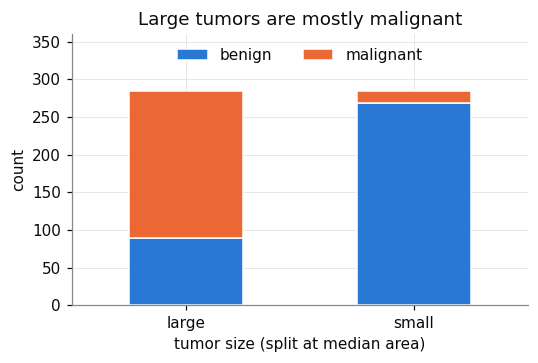

In [33]:
df["large"] = np.where(df["mean area"] > df["mean area"].median(), "large", "small")
tab = pd.crosstab(df["large"], df["group"])
print(tab)
chi2, p, dof, expected = stats.chi2_contingency(tab)
print(f"χ² = {chi2:.1f}, 自由度 = {dof}, p = {p:.2e}")
print("期待度数（5 未満があれば Fisher の正確検定を使う）:")
print(pd.DataFrame(expected, index=tab.index, columns=tab.columns).round(1))

tab.plot(kind="bar", stacked=True, color=[BLUE, ORANGE], figsize=(5, 3.4), edgecolor="white", rot=0)
plt.ylabel("count"); plt.xlabel("tumor size (split at median area)"); plt.ylim(0, 360)
plt.title("Large tumors are mostly malignant")
plt.legend(frameon=False, ncol=2, loc="upper center"); plt.tight_layout(); plt.show()